# GAN ile Nöral Ağ Üretmek — MNIST üzerinde bir "HyperGAN" deneyi

Sezgin doğru: bir görüntü de bir ağırlık kümesi de sonuçta tensör. Bu fikir literatürde gerçekten var: **HyperNetworks** (Ha vd., 2016), **HyperGAN** (Ratzlaff & Fuxin, 2019), eğitilmiş checkpoint'ler üzerinde üretici modeller (**G.pt**, Peebles vd., 2022) ve ağırlık uzayında difüzyon (**Neural Network Diffusion / p-diff**, Wang vd., 2024). Ana akım olmamasının üç temel nedeni var:

1. **Permütasyon simetrisi.** Bir MLP'nin gizli nöronlarının sırasını değiştirirsen fonksiyon aynı kalır ama ağırlık vektörü tamamen farklılaşır. Yani aynı "içerik", ağırlık uzayında astronomik sayıda kopya mod olarak yaşar; naif bir GAN bu modların arasını doldurup çalışmayan ağlar üretir. Görüntülerde böyle bir simetri yok: pikselleri karıştırırsan görüntü bozulur, komşu pikseller korelasyonludur ve CNN'ler bu yerelliği sömürür.
2. **Veri seti üretmek pahalı.** Görüntü GAN'ının verisi internetten toplanır; ağırlık GAN'ının verisi ise *binlerce eğitilmiş ağ* demek ("model zoo"). Her bir örnek, başlı başına bir eğitim koşusu.
3. **Boyut/örnek dengesizliği.** Birkaç yüz örnek + on binlerce boyut → discriminator anında ezberler.

Bu defterde üç hileyle bu sorunları aşıyoruz:

- Zoo'daki tüm ağları **aynı başlangıç ağırlıklarından** eğitiyoruz → ağırlıklar hizalanır, permütasyon sorunu fiilen ortadan kalkar, dağılım tek bir "vadide" toplanır.
- GAN'ı **boyut bazında normalize edilmiş** ağırlık uzayında çalıştırıyoruz.
- Adversarial kayba **fonksiyonel görev kaybı** ekliyoruz: üretilen vektörü `torch.func.functional_call` ile iskelet bir ağa giydirip gerçek MNIST batch'inde cross-entropy hesaplıyor ve gradyanı generatöre geri yayıyoruz. Ağırlık üretiminin görüntü üretimine karşı gizli avantajı bu: **"çıktı gerçekten çalışıyor mu?" sorusunun türevlenebilir bir cevabı var.** (`lambda_task = 0` yaparak saf adversarial versiyonu da deneyebilirsin — neden zorlandığını bizzat görürsün.)

**Deney planı** (senin tarifin):

1. **Faz 0 — Zoo:** 0–8 rakamlarını sınıflandıran çok sayıda küçük MLP eğit.
2. **Faz 1 — GAN:** Bu ağırlık vektörleri üzerinde GAN eğit; ürettiği ağların 9-sınıf doğruluğunu ölç.
3. **Faz 2 — Few-shot:** GAN'ın hiç görmediği rakamın (varsayılan: **9**) yalnızca `K_shot` örneğiyle generatörü fine-tune et; artık 10 rakamı da tanıyan ağlar üretiyor mu bak. Kıyas için aynı veriyle tek bir ağı klasik yolla fine-tune eden bir baseline da var.

Tahmini süre: GPU'da ~3–5 dk, CPU'da ~10–25 dk. (CPU'da acelen varsa `zoo_size=120`, `gan_steps=1500` yap.)

## 0) Ortam kurulumu (Anaconda)

Anaconda Prompt / terminalde sırasıyla:

```bash
# 1) yeni environment
conda create -n hypergan python=3.11 -y
conda activate hypergan

# 2) PyTorch — NVIDIA GPU'n varsa (CUDA 12.x):
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
#    GPU yoksa bunun yerine:
# pip install torch torchvision

# 3) yardımcı paketler + Jupyter
pip install numpy matplotlib tqdm ipywidgets jupyterlab

# 4) başlat
jupyter lab
```

Açılan arayüzde bu dosyayı açıp hücreleri yukarıdan aşağıya sırayla çalıştır. Bir sonraki hücre cihazı yazdırır; GPU kurduysan `cuda` görmelisin. (Kendi CUDA sürümüne özel komut için pytorch.org üzerindeki "Get Started" sayfasına bakabilirsin — `cu121` çoğu güncel sürücüyle çalışır.)

In [1]:
import math, copy, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.func import functional_call
from torch.nn.utils.parametrizations import spectral_norm
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

CFG = dict(
    # --- hedef sınıflandırıcı (GAN'ın üreteceği "ürün") ---
    img_size      = 14,     # MNIST 28x28 -> 14x14 (üretilecek parametre vektörünü küçük tutar)
    hidden        = 32,
    n_class       = 10,     # çıkış HER ZAMAN 10 nöron: görülmemiş sınıfın "yeri" baştan ayrılır
    unseen_digit  = 9,      # GAN'ın faz-1'de hiç görmeyeceği rakam

    # --- faz 0: model zoo ---
    zoo_size      = 250,    # kaç adet sınıflandırıcı eğitilecek
    zoo_subset    = 8000,   # her zoo üyesinin gördüğü örnek sayısı
    zoo_epochs    = 2,
    zoo_bs        = 128,
    zoo_lr        = 2e-3,

    # --- faz 1: GAN ---
    z_dim         = 64,
    gan_steps     = 3000,
    gan_bs        = 64,
    g_lr          = 1e-4,
    d_lr          = 2e-4,
    lambda_task   = 2.0,    # fonksiyonel görev kaybının ağırlığı (0 = saf GAN, dene!)
    task_img_bs   = 256,    # görev kaybı için görüntü batch boyutu
    nets_per_step = 6,      # her G adımında görevle test edilen üretilmiş ağ sayısı
    inst_noise    = 0.05,   # discriminator girişine eklenen gürültü (ezber freni)

    # --- faz 2: few-shot ---
    K_shot           = 20,  # görülmemiş rakamdan kaç örnek (5 / 10 / 50 dene!)
    replay_per_class = 100, # eski sınıflardan tekrar (replay) örnek sayısı
    ft_steps         = 600,
    ft_lr            = 1e-4,
    ft_img_bs        = 256,

    eval_nets     = 16,     # değerlendirmede G'den örneklenecek ağ sayısı
    seed          = 0,
)

torch.manual_seed(CFG['seed']); np.random.seed(CFG['seed'])
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('cihaz:', dev, '| torch', torch.__version__)

cihaz: cuda | torch 2.5.1+cu121


In [2]:
from torchvision import datasets

def load_split(train):
    ds = datasets.MNIST(root='./data', train=train, download=True)
    x = ds.data.float().unsqueeze(1) / 255.0                       # [N,1,28,28]
    x = F.interpolate(x, size=(CFG['img_size'], CFG['img_size']),
                      mode='bilinear', antialias=True)
    x = (x - 0.1307) / 0.3081
    return x.flatten(1).to(dev), ds.targets.to(dev)

Xtr, ytr = load_split(True)
Xte, yte = load_split(False)

known = ytr != CFG['unseen_digit']
Xtr_k, ytr_k = Xtr[known], ytr[known]            # eğitim: sadece 0-8

kte = yte != CFG['unseen_digit']
Xte_k, yte_k = Xte[kte], yte[kte]                # 9 sınıflı test; tam test = (Xte, yte)

# görülmemiş rakamdan K adet örnek ayır (faz-2'nin "çok az verisi")
g = torch.Generator().manual_seed(CFG['seed'])
idx9 = (ytr == CFG['unseen_digit']).nonzero().squeeze(1)
perm = torch.randperm(idx9.numel(), generator=g).to(dev)
idx9 = idx9[perm][:CFG['K_shot']]
X9, y9 = Xtr[idx9], ytr[idx9]

print(f"eğitim (0-8): {tuple(Xtr_k.shape)} | test (0-8): {tuple(Xte_k.shape)}")
print(f"rakam {CFG['unseen_digit']} için ayrılan örnek sayısı: {X9.shape[0]}")

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████████████████████████████████████████████████████| 9.91M/9.91M [00:01<00:00, 5.41MB/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|███████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 280kB/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|███████████████████████████████████████████████████████████| 1.65M/1.65M [00:02<00:00, 555kB/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 2.98MB/s]


Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw

eğitim (0-8): (54051, 196) | test (0-8): (8991, 196)
rakam 9 için ayrılan örnek sayısı: 20


In [3]:
class TargetNet(nn.Module):
    # Üretilecek "ürün": küçük bir MLP sınıflandırıcı
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(CFG['img_size'] ** 2, CFG['hidden'])
        self.fc2 = nn.Linear(CFG['hidden'], CFG['n_class'])
    def forward(self, x):
        return self.fc2(F.relu(self.fc1(x)))

base = TargetNet().to(dev)                        # functional_call için iskelet
BASE_STATE = copy.deepcopy(base.state_dict())     # tüm zoo üyeleri AYNI başlangıçtan başlayacak
P_INFO = [(n, p.shape, p.numel()) for n, p in base.named_parameters()]
D_PARAM = sum(ne for _, _, ne in P_INFO)
print(f"hedef ağın parametre sayısı (GAN çıktı vektörünün boyutu): {D_PARAM}")

def flatten_params(model):
    return torch.cat([p.detach().reshape(-1) for _, p in model.named_parameters()])

def vec_to_params(v):
    out, i = {}, 0
    for n, shp, ne in P_INFO:
        out[n] = v[i:i + ne].view(shp)
        i += ne
    return out

def net_forward(v, X):
    # ağırlık vektörü v'yi iskelete "giydirip" ileri geçiş yapar — v'ye göre TÜREVLENEBİLİR
    return functional_call(base, vec_to_params(v), (X,))

@torch.no_grad()
def eval_vec(v, X, y):
    pred = net_forward(v, X).argmax(1)
    overall = (pred == y).float().mean().item()
    per = [((pred[y == c] == c).float().mean().item() if (y == c).any() else float('nan'))
           for c in range(10)]
    return overall, per

@torch.no_grad()
def eval_ensemble(vs, X, y):
    prob = torch.zeros(X.shape[0], 10, device=dev)
    for v in vs:
        prob += F.softmax(net_forward(v, X), dim=1)
    pred = prob.argmax(1)
    overall = (pred == y).float().mean().item()
    per = [((pred[y == c] == c).float().mean().item() if (y == c).any() else float('nan'))
           for c in range(10)]
    return overall, per

hedef ağın parametre sayısı (GAN çıktı vektörünün boyutu): 6634


## 1) Faz 0 — Model zoo: GAN'ın "veri seti"

Görüntü GAN'ı piksel matrisleriyle besleniyorsa, bizimki eğitilmiş ağırlık vektörleriyle beslenmeli. Aşağıda `zoo_size` adet küçük MLP'yi (196 → 32 → 10) yalnızca 0–8 rakamları üzerinde eğitiyoruz. İki kritik detay:

- Her ağ **aynı başlangıç ağırlıklarından** başlıyor ama farklı veri alt kümesi ve farklı karıştırma sırası görüyor. Bu, ağları ağırlık uzayında hizalı tutar (permütasyon simetrisini fiilen kırar) — bu numara olmadan GAN'ın işi neredeyse imkânsızdır.
- Çıkış katmanı baştan **10 nöronlu**: görülmemiş rakamın satırı mimaride var ama hiç eğitilmediği için "ölü". Faz 2'de o satırı uyandırmaya çalışacağız.

model zoo:   0%|          | 0/250 [00:00<?, ?it/s]

süre: 23 sn | zoo test doğruluğu: 0.906 ± 0.003


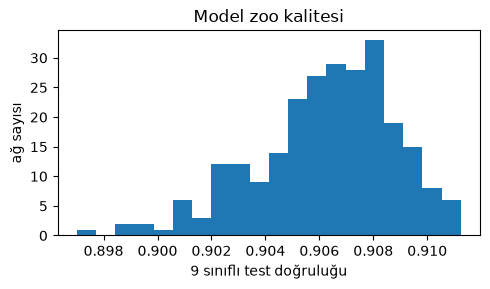

In [4]:
def train_zoo_member():
    net = TargetNet().to(dev)
    net.load_state_dict(BASE_STATE)               # simetri kırıcı hile: sabit başlangıç
    opt = torch.optim.Adam(net.parameters(), lr=CFG['zoo_lr'])
    sub = torch.randperm(Xtr_k.shape[0], device=dev)[:CFG['zoo_subset']]
    for _ in range(CFG['zoo_epochs']):
        order = sub[torch.randperm(sub.numel(), device=dev)]
        for s in range(0, order.numel(), CFG['zoo_bs']):
            b = order[s:s + CFG['zoo_bs']]
            loss = F.cross_entropy(net(Xtr_k[b]), ytr_k[b])
            opt.zero_grad(); loss.backward(); opt.step()
    return flatten_params(net)

t0 = time.time()
zoo, zoo_acc = [], []
for _ in tqdm(range(CFG['zoo_size']), desc='model zoo'):
    v = train_zoo_member()
    zoo.append(v)
    zoo_acc.append(eval_vec(v, Xte_k, yte_k)[0])
zoo = torch.stack(zoo)                             # [zoo_size, D_PARAM]
zoo_acc = np.array(zoo_acc)
print(f"süre: {time.time() - t0:.0f} sn | zoo test doğruluğu: {zoo_acc.mean():.3f} ± {zoo_acc.std():.3f}")

plt.figure(figsize=(5, 3))
plt.hist(zoo_acc, bins=20)
plt.xlabel('9 sınıflı test doğruluğu'); plt.ylabel('ağ sayısı'); plt.title('Model zoo kalitesi')
plt.tight_layout(); plt.show()

In [5]:
MU  = zoo.mean(0)
SIG = zoo.std(0).clamp_min(1e-4)
zoo_n = (zoo - MU) / SIG                           # GAN bu normalize uzayda çalışacak

def to_weights(v_norm):
    # normalize uzaydan gerçek ağırlık uzayına dönüş
    return v_norm * SIG + MU

def pca_2d(ref, other):
    # ref üzerinde PCA öğren, her ikisini de aynı düzleme izdüşür
    m = ref.mean(0, keepdim=True)
    _, _, Vh = torch.linalg.svd((ref - m).cpu(), full_matrices=False)
    P = Vh[:2].T
    return ((ref - m).cpu() @ P).numpy(), ((other - m).cpu() @ P).numpy()

print('normalizasyon hazır | zoo_n:', tuple(zoo_n.shape))

normalizasyon hazır | zoo_n: (250, 6634)


## 2) Faz 1 — GAN

- **Generator:** `z ~ N(0, I)` → normalize ağırlık vektörü (boyut: `D_PARAM`).
- **Discriminator:** spectral norm'lu MLP. Elimizde sadece birkaç yüz gerçek örnek olduğundan ezberi frenlemek için girişine gürültü ekliyor ve label smoothing kullanıyoruz.
- **Generator kaybı = adversarial + λ · görev.** Adversarial terim, üretimi "gerçek eğitilmiş ağların dağılımına" benzetir; görev terimi ise üretilen ağı gerçek MNIST batch'inde çalıştırıp CE kaybını generatöre geri yayar.

Güzel bir yan etki: normalizasyon sayesinde G, eğitimin en başında yaklaşık olarak "zoo ortalaması" ağı üretir. Hizalı bir zoo'da bu ortalama zaten iş gören bir sınıflandırıcıdır — eğitim bu yüzden çok stabil başlar.

In [6]:
class Generator(nn.Module):
    def __init__(self, z_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LayerNorm(256), nn.ReLU(),
            nn.Linear(256, 512),   nn.LayerNorm(512), nn.ReLU(),
            nn.Linear(512, out_dim),
        )
    def forward(self, z):
        return self.net(z)

class Critic(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            spectral_norm(nn.Linear(in_dim, 512)), nn.LeakyReLU(0.2),
            spectral_norm(nn.Linear(512, 256)),    nn.LeakyReLU(0.2),
            spectral_norm(nn.Linear(256, 1)),
        )
    def forward(self, w):
        return self.net(w).squeeze(1)

Gnet = Generator(CFG['z_dim'], D_PARAM).to(dev)
Dnet = Critic(D_PARAM).to(dev)
optG = torch.optim.Adam(Gnet.parameters(), lr=CFG['g_lr'], betas=(0.5, 0.999))
optD = torch.optim.Adam(Dnet.parameters(), lr=CFG['d_lr'], betas=(0.5, 0.999))
bce  = nn.BCEWithLogitsLoss()

def task_loss(gen_vnorm, X, y):
    # üretilen her ağı gerçek görüntülerde dener; CE kaybı generatöre geri yayılır
    losses = [F.cross_entropy(net_forward(to_weights(v), X), y) for v in gen_vnorm]
    return torch.stack(losses).mean()

print(f"Generator: {sum(p.numel() for p in Gnet.parameters()):,} parametre | "
      f"Critic: {sum(p.numel() for p in Dnet.parameters()):,} parametre")

Generator: 3,553,002 parametre | Critic: 3,528,705 parametre


GAN faz-1:   0%|          | 0/3000 [00:00<?, ?it/s]

adım     1 | D 1.362 | G_adv 1.754 | görev CE 0.399 | üretilen ağ doğruluğu 0.908
adım   500 | D 0.393 | G_adv 3.197 | görev CE 0.289 | üretilen ağ doğruluğu 0.908
adım  1000 | D 0.379 | G_adv 3.722 | görev CE 0.377 | üretilen ağ doğruluğu 0.909
adım  1500 | D 0.337 | G_adv 4.877 | görev CE 0.364 | üretilen ağ doğruluğu 0.908
adım  2000 | D 0.355 | G_adv 4.394 | görev CE 0.432 | üretilen ağ doğruluğu 0.908
adım  2500 | D 0.339 | G_adv 4.998 | görev CE 0.408 | üretilen ağ doğruluğu 0.908
adım  3000 | D 0.336 | G_adv 5.533 | görev CE 0.336 | üretilen ağ doğruluğu 0.908


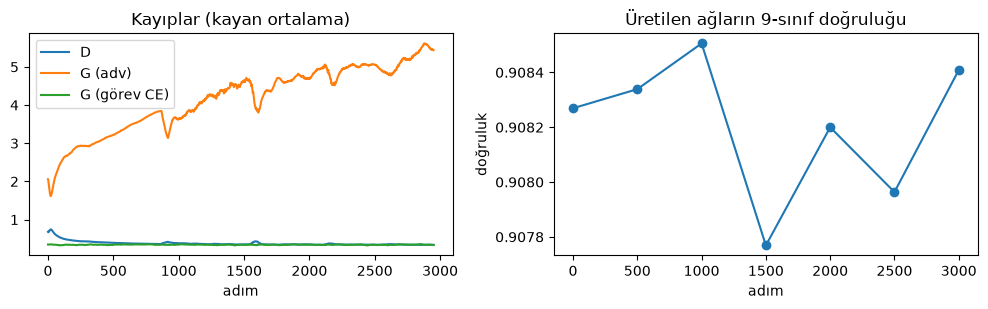

In [7]:
hist = {'d': [], 'g_adv': [], 'g_task': [], 'eval_step': [], 'eval_acc': []}
noise = CFG['inst_noise']

for step in tqdm(range(1, CFG['gan_steps'] + 1), desc='GAN faz-1'):
    # ---- Discriminator ----
    idx  = torch.randint(0, zoo_n.shape[0], (CFG['gan_bs'],), device=dev)
    real = zoo_n[idx] + noise * torch.randn(CFG['gan_bs'], D_PARAM, device=dev)
    with torch.no_grad():
        fake = Gnet(torch.randn(CFG['gan_bs'], CFG['z_dim'], device=dev))
    fake = fake + noise * torch.randn_like(fake)
    d_loss = (bce(Dnet(real), torch.full((CFG['gan_bs'],), 0.9, device=dev))
              + bce(Dnet(fake), torch.zeros(CFG['gan_bs'], device=dev)))
    optD.zero_grad(); d_loss.backward(); optD.step()

    # ---- Generator: adversarial + fonksiyonel görev kaybı ----
    z_adv = torch.randn(CFG['gan_bs'], CFG['z_dim'], device=dev)
    g_adv = bce(Dnet(Gnet(z_adv) + noise * torch.randn(CFG['gan_bs'], D_PARAM, device=dev)),
                torch.ones(CFG['gan_bs'], device=dev))
    z_t = torch.randn(CFG['nets_per_step'], CFG['z_dim'], device=dev)
    b   = torch.randint(0, Xtr_k.shape[0], (CFG['task_img_bs'],), device=dev)
    g_task = task_loss(Gnet(z_t), Xtr_k[b], ytr_k[b])
    g_loss = g_adv + CFG['lambda_task'] * g_task
    optG.zero_grad(); g_loss.backward(); optG.step()

    hist['d'].append(d_loss.item()); hist['g_adv'].append(g_adv.item()); hist['g_task'].append(g_task.item())

    if step == 1 or step % 500 == 0:
        with torch.no_grad():
            vs = Gnet(torch.randn(8, CFG['z_dim'], device=dev))
        acc = float(np.mean([eval_vec(to_weights(v), Xte_k, yte_k)[0] for v in vs]))
        hist['eval_step'].append(step); hist['eval_acc'].append(acc)
        tqdm.write(f"adım {step:5d} | D {d_loss.item():.3f} | G_adv {g_adv.item():.3f} "
                   f"| görev CE {g_task.item():.3f} | üretilen ağ doğruluğu {acc:.3f}")

def smooth(a, k=50):
    a = np.asarray(a, dtype=float)
    return a if len(a) < k else np.convolve(a, np.ones(k) / k, mode='valid')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(smooth(hist['d']), label='D')
ax[0].plot(smooth(hist['g_adv']), label='G (adv)')
ax[0].plot(smooth(hist['g_task']), label='G (görev CE)')
ax[0].set_xlabel('adım'); ax[0].legend(); ax[0].set_title('Kayıplar (kayan ortalama)')
ax[1].plot(hist['eval_step'], hist['eval_acc'], marker='o')
ax[1].set_xlabel('adım'); ax[1].set_ylabel('doğruluk'); ax[1].set_title('Üretilen ağların 9-sınıf doğruluğu')
plt.tight_layout(); plt.show()

Üretilen 16 ağın 9-sınıf doğruluğu: 0.909 ± 0.001   (zoo ortalaması: 0.906)
Görülmemiş rakamın (9) recall değeri: 0.000   (beklenen: ~0)
16 ağın ensemble (topluluk) doğruluğu: 0.908
çift başına tahmin uyuşmazlığı: 0.0056 | ort. çift mesafesi -> üretilen: 22.9, zoo: 114.4


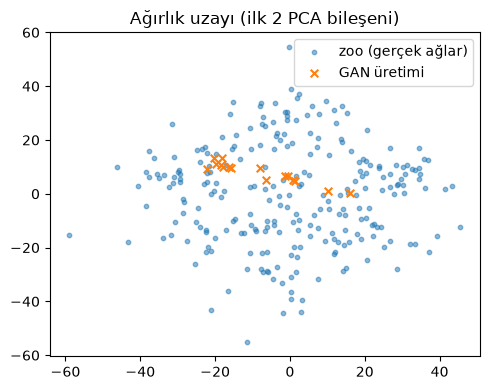

In [8]:
with torch.no_grad():
    Zs    = torch.randn(CFG['eval_nets'], CFG['z_dim'], device=dev)
    gen_n = Gnet(Zs)
    gen_w = to_weights(gen_n)

res9 = [eval_vec(v, Xte_k, yte_k) for v in gen_w]
acc9 = np.array([r[0] for r in res9])
print(f"Üretilen {CFG['eval_nets']} ağın 9-sınıf doğruluğu: {acc9.mean():.3f} ± {acc9.std():.3f}"
      f"   (zoo ortalaması: {zoo_acc.mean():.3f})")

res10  = [eval_vec(v, Xte, yte) for v in gen_w]
digit9 = np.array([r[1][CFG['unseen_digit']] for r in res10])
print(f"Görülmemiş rakamın ({CFG['unseen_digit']}) recall değeri: {digit9.mean():.3f}   (beklenen: ~0)")

ens9, _ = eval_ensemble(list(gen_w), Xte_k, yte_k)
print(f"{CFG['eval_nets']} ağın ensemble (topluluk) doğruluğu: {ens9:.3f}")

# Çeşitlilik: üretilen ağlar birbirinin kopyası mı?
with torch.no_grad():
    preds = torch.stack([net_forward(v, Xte_k).argmax(1) for v in gen_w])
disagree = (preds[:, None, :] != preds[None, :, :]).float().mean().item()
dist_gen = torch.pdist(gen_n.cpu()).mean().item()
dist_zoo = torch.pdist(zoo_n.cpu()).mean().item()
print(f"çift başına tahmin uyuşmazlığı: {disagree:.4f} | ort. çift mesafesi -> üretilen: {dist_gen:.1f}, zoo: {dist_zoo:.1f}")

pz, pg = pca_2d(zoo_n, gen_n)
plt.figure(figsize=(5, 4))
plt.scatter(pz[:, 0], pz[:, 1], s=10, alpha=0.5, label='zoo (gerçek ağlar)')
plt.scatter(pg[:, 0], pg[:, 1], s=30, marker='x', label='GAN üretimi')
plt.legend(); plt.title('Ağırlık uzayı (ilk 2 PCA bileşeni)')
plt.tight_layout(); plt.show()

## 3) Faz 2 — Görülmemiş rakamı `K_shot` örnekle ekleme

Generatörü, rakam 9'un `K_shot` örneği + eski sınıflardan küçük bir **replay** karışımı üzerinde, yalnızca görev kaybıyla ve düşük öğrenme oranıyla fine-tune ediyoruz. Replay şart: onsuz 0–8 bilgisi hızla bozulur (catastrophic forgetting). Rakam 9 örnekleri, sınıflar dengelensin diye çoğaltılıyor.

Adil kıyas için baseline: aynı veri ve aynı adım sayısıyla, zoo'dan tek bir ağı klasik şekilde fine-tune ediyoruz. Dürüst beklenti: tek-ağ baseline genellikle benzer (bazen daha iyi) skor alır — bu deneyin iddiası "GAN, transfer öğrenmeyi yener" değil. Kazanç, tek bir ağ yerine bir **ağ dağılımı** elde etmek: bedava ensemble, çeşitlilik, belirsizlik kestirimi. `K_shot` değerini 5 / 10 / 50 yapıp farkı izle.

In [9]:
# Fine-tune veri seti: 0-8'den replay + rakam 9'un K örneği (dengelemek için çoğaltılır)
g2 = torch.Generator().manual_seed(CFG['seed'] + 1)
parts_X, parts_y = [], []
for c in range(10):
    if c == CFG['unseen_digit']:
        continue
    idc  = (ytr == c).nonzero().squeeze(1)
    pick = idc[torch.randperm(idc.numel(), generator=g2)[:CFG['replay_per_class']].to(dev)]
    parts_X.append(Xtr[pick]); parts_y.append(ytr[pick])
reps = math.ceil(CFG['replay_per_class'] / CFG['K_shot'])
parts_X.append(X9.repeat(reps, 1)); parts_y.append(y9.repeat(reps))
X_ft = torch.cat(parts_X); y_ft = torch.cat(parts_y)
print(f"fine-tune veri seti: {tuple(X_ft.shape)} | rakam {CFG['unseen_digit']} (tekrarlı): {reps * CFG['K_shot']} örnek")

# --- Kıyas (baseline): TEK bir zoo ağını aynı veriyle klasik şekilde fine-tune et ---
bl = TargetNet().to(dev)
bl.load_state_dict({n: t.clone() for n, t in vec_to_params(zoo[0]).items()})
optB = torch.optim.Adam(bl.parameters(), lr=1e-3)
for _ in range(CFG['ft_steps']):
    b = torch.randint(0, X_ft.shape[0], (CFG['ft_img_bs'],), device=dev)
    loss = F.cross_entropy(bl(X_ft[b]), y_ft[b])
    optB.zero_grad(); loss.backward(); optB.step()
bl_overall, bl_per = eval_vec(flatten_params(bl), Xte, yte)
print(f"Baseline (tek ağ): 10-sınıf genel {bl_overall:.3f} | rakam {CFG['unseen_digit']} recall {bl_per[CFG['unseen_digit']]:.3f}")

fine-tune veri seti: (1000, 196) | rakam 9 (tekrarlı): 100 örnek
Baseline (tek ağ): 10-sınıf genel 0.894 | rakam 9 recall 0.771


GAN faz-2 (few-shot):   0%|          | 0/600 [00:00<?, ?it/s]

adım    1 | CE 1.779 | 10-sınıf genel 0.817 | rakam 9 recall 0.000
adım  100 | CE 0.616 | 10-sınıf genel 0.814 | rakam 9 recall 0.000
adım  200 | CE 0.380 | 10-sınıf genel 0.877 | rakam 9 recall 0.728
adım  300 | CE 0.293 | 10-sınıf genel 0.889 | rakam 9 recall 0.789
adım  400 | CE 0.187 | 10-sınıf genel 0.889 | rakam 9 recall 0.792
adım  500 | CE 0.235 | 10-sınıf genel 0.892 | rakam 9 recall 0.800
adım  600 | CE 0.123 | 10-sınıf genel 0.895 | rakam 9 recall 0.805


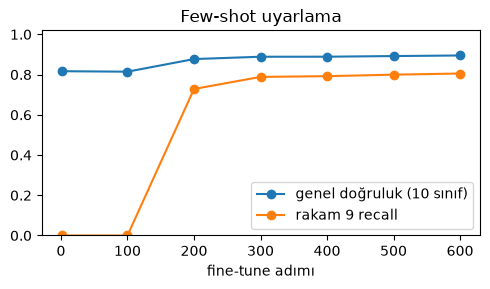

In [10]:
G2 = copy.deepcopy(Gnet)
optG2 = torch.optim.Adam(G2.parameters(), lr=CFG['ft_lr'])
ft_curve = []

for step in tqdm(range(1, CFG['ft_steps'] + 1), desc='GAN faz-2 (few-shot)'):
    z = torch.randn(CFG['nets_per_step'], CFG['z_dim'], device=dev)
    b = torch.randint(0, X_ft.shape[0], (CFG['ft_img_bs'],), device=dev)
    loss = task_loss(G2(z), X_ft[b], y_ft[b])
    optG2.zero_grad(); loss.backward(); optG2.step()

    if step == 1 or step % 100 == 0:
        with torch.no_grad():
            vs = G2(torch.randn(8, CFG['z_dim'], device=dev))
        r  = [eval_vec(to_weights(v), Xte, yte) for v in vs]
        ov = float(np.mean([x[0] for x in r]))
        d9 = float(np.mean([x[1][CFG['unseen_digit']] for x in r]))
        ft_curve.append((step, ov, d9))
        tqdm.write(f"adım {step:4d} | CE {loss.item():.3f} | 10-sınıf genel {ov:.3f} | rakam {CFG['unseen_digit']} recall {d9:.3f}")

fc = np.array(ft_curve)
plt.figure(figsize=(5, 3))
plt.plot(fc[:, 0], fc[:, 1], marker='o', label='genel doğruluk (10 sınıf)')
plt.plot(fc[:, 0], fc[:, 2], marker='o', label=f"rakam {CFG['unseen_digit']} recall")
plt.xlabel('fine-tune adımı'); plt.ylim(0, 1.02); plt.legend()
plt.title('Few-shot uyarlama'); plt.tight_layout(); plt.show()

Faz-1 G   : genel 0.817 ± 0.000 | rakam 9 recall 0.000
Faz-2 G   : genel 0.895 ± 0.001 | rakam 9 recall 0.801
Faz-2 ens.: genel 0.896           | rakam 9 recall 0.805
Baseline  : genel 0.894           | rakam 9 recall 0.771


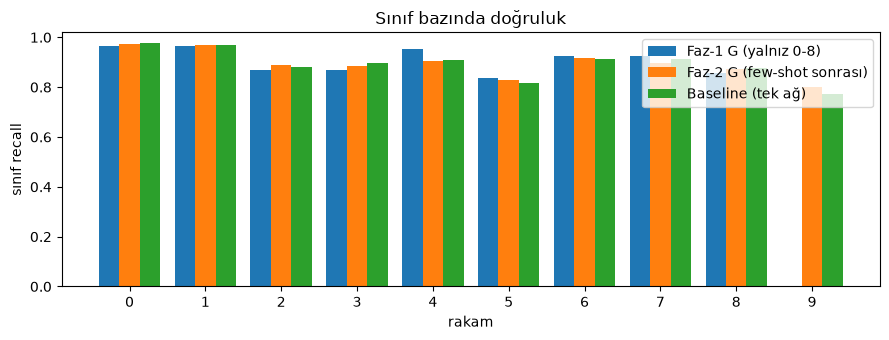

modeller kaydedildi: hypergan_mnist.pt


In [11]:
with torch.no_grad():
    Zs = torch.randn(CFG['eval_nets'], CFG['z_dim'], device=dev)
    gen1_w = to_weights(Gnet(Zs))   # faz-1 generatörü (aynı z değerleriyle — adil kıyas)
    gen2_w = to_weights(G2(Zs))     # faz-2 generatörü

res1 = [eval_vec(v, Xte, yte) for v in gen1_w]
res2 = [eval_vec(v, Xte, yte) for v in gen2_w]
ov1 = np.array([r[0] for r in res1]); per1 = np.array([r[1] for r in res1])
ov2 = np.array([r[0] for r in res2]); per2 = np.array([r[1] for r in res2])
ens_ov, ens_per = eval_ensemble(list(gen2_w), Xte, yte)
ud = CFG['unseen_digit']

print(f"Faz-1 G   : genel {ov1.mean():.3f} ± {ov1.std():.3f} | rakam {ud} recall {per1[:, ud].mean():.3f}")
print(f"Faz-2 G   : genel {ov2.mean():.3f} ± {ov2.std():.3f} | rakam {ud} recall {per2[:, ud].mean():.3f}")
print(f"Faz-2 ens.: genel {ens_ov:.3f}           | rakam {ud} recall {ens_per[ud]:.3f}")
print(f"Baseline  : genel {bl_overall:.3f}           | rakam {ud} recall {bl_per[ud]:.3f}")

x = np.arange(10); w = 0.27
plt.figure(figsize=(9, 3.5))
plt.bar(x - w, per1.mean(0), w, label='Faz-1 G (yalnız 0-8)')
plt.bar(x,     per2.mean(0), w, label='Faz-2 G (few-shot sonrası)')
plt.bar(x + w, bl_per,       w, label='Baseline (tek ağ)')
plt.xticks(x); plt.ylim(0, 1.02); plt.xlabel('rakam'); plt.ylabel('sınıf recall')
plt.legend(); plt.title('Sınıf bazında doğruluk'); plt.tight_layout(); plt.show()

torch.save({'G_faz1': Gnet.state_dict(), 'G_faz2': G2.state_dict(),
            'MU': MU.cpu(), 'SIG': SIG.cpu(), 'CFG': CFG}, 'hypergan_mnist.pt')
print('modeller kaydedildi: hypergan_mnist.pt')

## 4) Ne gördük, sınırlar neler?

Muhtemel gözlemlerin: Faz-1 G'nin ürettiği ağlar zoo ortalamasına yakın doğrulukta çalışır ve rakam 9'u hiç bilmez (recall ≈ 0 — mimaride yeri olmasına rağmen o çıkış nöronu ölüdür). Faz-2'den sonra **aynı generatör**, 10 sınıfı da tanıyan ağlar örneklemeye başlar; `K_shot` büyüdükçe rakam 9 recall'u yükselir. Ensemble tek tek ağlardan genellikle biraz daha iyidir — generatör bir "sınıflandırıcı dağılımı" olduğu için bunu bedavaya alırız.

Bunun bir oyuncak olduğu yerler ve gerçek dünyada ne yapıldığı:

- **Ölçek.** Burada ~6.6k parametrelik ağlar üretiyoruz; generatörün son katmanı bile `512 × D_PARAM` boyutunda. Milyonlarca parametreli hedeflerde düz MLP generator patlar → katman katman / parça parça üretim, latent uzayda üretim, difüzyon.
- **Sabit başlangıç hilesi** genel durumda elde yok: farklı init'lerle eğitilmiş ağları modellemek için permütasyon-eşdeğer mimariler (weight-space learning), ağ hizalama (Git Re-Basin) veya permütasyon augmentasyonu gerekir.
- **GAN yerine difüzyon.** Güncel çalışmalar (G.pt, p-diff) checkpoint üretiminde difüzyon kullanıyor; mod çökmesine karşı çok daha dayanıklı.

Kurcalamak istersen: `unseen_digit` değerini değiştir; `lambda_task = 0` ile saf GAN dene; `K_shot = 5` ile gerçek few-shot zorluğunu gör; `hidden` ve `img_size` değerlerini büyütüp ölçeklenme sancısını bizzat hisset.

**Okuma listesi:** Ha vd., *HyperNetworks* (2016) · Ratzlaff & Fuxin, *HyperGAN* (2019) · Peebles vd., *Learning to Learn with Generative Models of Neural Network Checkpoints* (2022) · Wang vd., *Neural Network Diffusion* (2024) · Schürholt vd., model zoo / weight-space learning çalışmaları.